# NB3 — Bổ sung metric, confusion matrix, ablation kiến trúc mạng
### (trên mô hình DÙNG CHUNG PhoBERT + ViT — chuẩn duy nhất)

Từ nay **một mô hình dùng chung** (PhoBERT+ViT, NB2) là kiến trúc chuẩn cho mọi
thực nghiệm — không dùng lại nhánh "mỗi câu một mô hình" (NB1) nữa. NB3 bổ sung
các phần còn thiếu của Chương 5, tất cả chạy trên chính model dùng chung:

1. **AUC-ROC, PR-AUC** (macro) trên xác suất sigmoid của model dùng chung.
2. **F1-weighted, Recall-micro/weighted**.
3. **Confusion matrix** cho các câu đơn nhãn.
4. **Ablation KIẾN TRÚC MẠNG**: bỏ Dropout, bỏ chuẩn hoá đầu vào, MLP 1 lớp
   (tuyến tính) vs 2 lớp (kiến trúc gốc) — đo đóng góp từng thành phần của mạng.
5. **Bảng thời gian train + suy luận** cho model dùng chung.

In [1]:
import os, sys, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
if os.path.basename(os.getcwd())!="experiments" and os.path.isdir("F:/VQA/experiments"):
    os.chdir("F:/VQA/experiments")
import unified as U
from sklearn.metrics import (accuracy_score, f1_score, recall_score, roc_auc_score,
                             average_precision_score, confusion_matrix)

vit=U.load_vit("_vitl"); pho=U.load_phobert()
tr=pd.read_csv(os.path.join(U.QA,"train.csv")); tr["qid"]=tr["qid"].astype(str)
va=pd.read_csv(os.path.join(U.QA,"val.csv"));   va["qid"]=va["qid"].astype(str)
te=pd.read_csv(os.path.join(U.QA,"test.csv"));  te["qid"]=te["qid"].astype(str)
full=pd.concat([tr,va,te],ignore_index=True)
vocab,idx,cand=U.build_global_vocab(full)
Xtr,Ytr,qtr,rtr=U.build_rows(tr,vit,pho,idx,"full")
Xte,Yte,qte,rte=U.build_rows(te,vit,pho,idx,"full")
print("Model dùng chung — đặc trưng:", Xtr.shape, "| GLOBAL atom vocab:", len(vocab))
model,sc,pos=U.train_shared(Xtr,Ytr,"baseline",epochs=80)
preds,P = U.predict_per_question(model,sc,Xte,qte,cand,"baseline",return_proba=True)
print("Đã huấn luyện xong model dùng chung baseline (dùng lại cho mọi phần dưới).")

Model dùng chung — đặc trưng: (13672, 1792) | GLOBAL atom vocab: 20


Đã huấn luyện xong model dùng chung baseline (dùng lại cho mọi phần dưới).


## 1. AUC-ROC & PR-AUC — nhóm đơn nhãn (theo từng câu)

Điểm số sigmoid trên tập atom ứng viên của từng câu (không cần chuẩn hoá tổng=1,
AUC-ROC/PR-AUC chỉ cần thứ tự điểm số). Kèm F1-weighted, Recall-micro/weighted.

In [2]:
rows=[]
for q in U.SINGLE_QIDS:
    m = qte==q; cd = cand[q]
    if m.sum()==0: continue
    Yt, Pp, Pr = Yte[m][:,cd], P[m][:,cd], preds[m][:,cd]
    gt=[vocab[cd[i]] for i in Yt.argmax(1)]; pr=[vocab[cd[i]] for i in Pr.argmax(1)]
    row = {"qid":q,"n_lớp":len(cd),
           "EM":round(accuracy_score(gt,pr),4),
           "F1_macro":round(f1_score(gt,pr,average="macro",zero_division=0),4),
           "F1_weighted":round(f1_score(gt,pr,average="weighted",zero_division=0),4),
           "R_macro":round(recall_score(gt,pr,average="macro",zero_division=0),4),
           "R_micro":round(recall_score(gt,pr,average="micro",zero_division=0),4),
           "R_weighted":round(recall_score(gt,pr,average="weighted",zero_division=0),4)}
    try:
        row["AUC_ROC"]=round(roc_auc_score(Yt,Pp,average="macro"),4)
        row["PR_AUC"]=round(average_precision_score(Yt,Pp,average="macro"),4)
    except Exception:
        row["AUC_ROC"]=np.nan; row["PR_AUC"]=np.nan
    rows.append(row)
single_extra = pd.DataFrame(rows)
single_extra.loc["TB"] = ["—","—"] + [round(single_extra[c].mean(),4) for c in single_extra.columns[2:]]
single_extra

,qid,n_lớp,EM,F1_macro,F1_weighted,R_macro,R_micro,R_weighted,AUC_ROC,PR_AUC
0,Q1,2,0.8575,0.8073,0.8502,0.7843,0.8575,0.8575,0.9112,0.8858
1,Q3,2,0.8374,0.8367,0.8371,0.8361,0.8374,0.8374,0.9084,0.9053
2,Q4,2,0.8788,0.6333,0.8424,0.6000,0.8788,0.8788,0.9268,0.8578
3,Q6,6,0.6516,0.4681,0.6232,0.5040,0.6516,0.6516,0.8655,0.5402
4,Q7,2,0.8947,0.7661,0.9097,0.8921,0.8947,0.8947,0.9511,0.8699
5,Q9,2,0.8045,0.6629,0.7910,0.6469,0.8045,0.8045,0.7529,0.6786
6,Q10,2,0.9104,0.7607,0.8977,0.7097,0.9104,0.9104,0.9177,0.8420
TB,—,—,0.8336,0.7050,0.8216,0.7104,0.8336,0.8336,0.8905,0.7971


## 2. AUC-ROC & PR-AUC — nhóm "what" (đa nhãn, nhãn nguyên tử)

In [3]:
rows=[]
for q in U.WHAT_QIDS:
    m = qte==q; cd = cand[q]
    Yt, Pp, Pr = Yte[m][:,cd].astype(int), P[m][:,cd], preds[m][:,cd].astype(int)
    mm = R = None
    import run_imbalance as RR
    mres = RR.multilabel_metrics(Yt,Pr)
    row = {"qid":q,"n_nhãn":len(cd),
           "exact":round(mres["exact"],4),"F1_macro":round(mres["F1_macro"],4),
           "F1_micro":round(mres["F1_micro"],4),
           "F1_weighted":round(f1_score(Yt,Pr,average="weighted",zero_division=0),4),
           "R_macro":round(mres["R_macro"],4),
           "R_micro":round(recall_score(Yt,Pr,average="micro",zero_division=0),4),
           "R_weighted":round(recall_score(Yt,Pr,average="weighted",zero_division=0),4)}
    try:
        row["AUC_ROC"]=round(roc_auc_score(Yt,Pp,average="macro"),4)
        row["PR_AUC"]=round(average_precision_score(Yt,Pp,average="macro"),4)
    except Exception:
        row["AUC_ROC"]=np.nan; row["PR_AUC"]=np.nan
    rows.append(row)
what_extra = pd.DataFrame(rows)
what_extra.loc["TB"] = ["—","—"] + [round(what_extra[c].mean(),4) for c in what_extra.columns[2:]]
what_extra

,qid,n_nhãn,exact,F1_macro,F1_micro,F1_weighted,R_macro,R_micro,R_weighted,AUC_ROC,PR_AUC
0,Q2,5,0.7643,0.7045,0.7848,0.7839,0.6732,0.7881,0.7881,0.9161,0.7644
1,Q5,4,0.8122,0.6785,0.8341,0.8235,0.6418,0.8233,0.8233,0.9346,0.7959
2,Q8,5,0.5586,0.6293,0.6734,0.6683,0.6293,0.6584,0.6584,0.8776,0.7097
TB,—,—,0.7117,0.6708,0.7641,0.7586,0.6481,0.7566,0.7566,0.9094,0.7567


## 3. Confusion matrix — các câu đơn nhãn (model dùng chung)

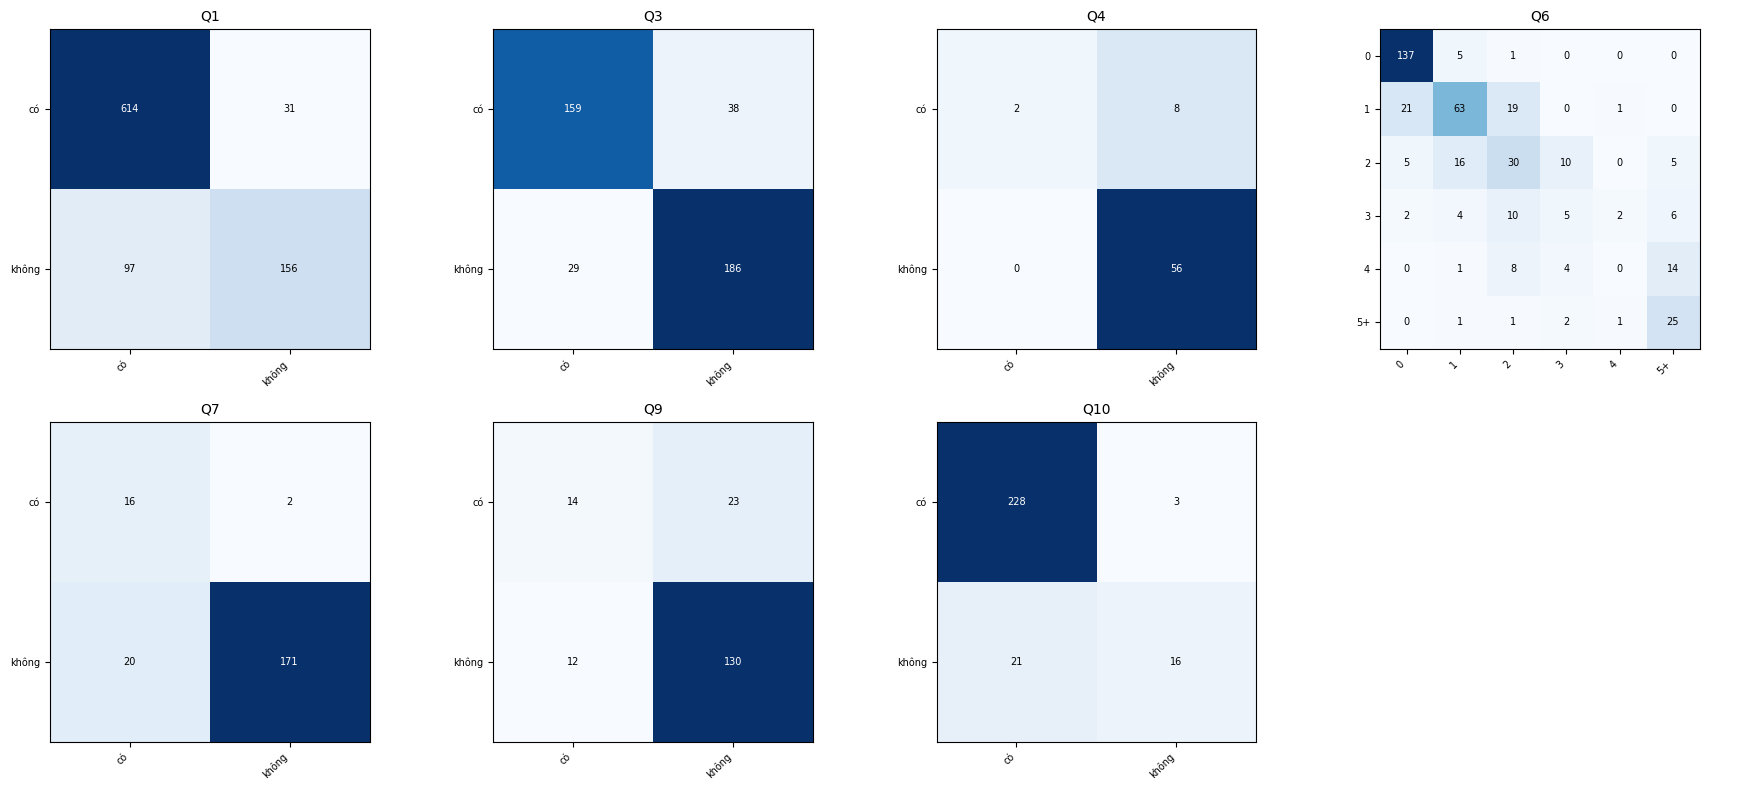

Đã lưu results/nb3_confusion_matrices.png


In [4]:
fig, axes = plt.subplots(2,4, figsize=(18,8))
for ax,q in zip(axes.flat, U.SINGLE_QIDS):
    m = qte==q; cd = cand[q]
    Yt, Pr = Yte[m][:,cd], preds[m][:,cd]
    classes=[vocab[i] for i in cd]
    gt=[classes[i] for i in Yt.argmax(1)]; pr=[classes[i] for i in Pr.argmax(1)]
    cm = confusion_matrix(gt, pr, labels=classes)
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha="right", fontsize=7)
    ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes, fontsize=7)
    ax.set_title(q, fontsize=10)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j,i,cm[i,j],ha="center",va="center",fontsize=7,
                    color="white" if cm[i,j]>cm.max()/2 else "black")
for ax in axes.flat[len(U.SINGLE_QIDS):]: ax.axis("off")
plt.tight_layout(); plt.savefig("results/nb3_confusion_matrices.png", dpi=110); plt.show()
print("Đã lưu results/nb3_confusion_matrices.png")

## 4. Ablation KIẾN TRÚC MẠNG (model dùng chung, đổi đúng 1 thành phần)

- **full**: MLP 2 lớp + StandardScaler + Dropout 0.3 (kiến trúc gốc NB2).
- **no-scaler**: bỏ chuẩn hoá đầu vào.
- **no-dropout**: bỏ Dropout.
- **linear-1layer**: bỏ tầng ẩn, chỉ còn 1 lớp tuyến tính.

In [5]:
variants = [("full",True,0.3,2), ("no-scaler",False,0.3,2),
            ("no-dropout",True,0.0,2), ("linear-1layer",True,0.0,1)]
rows=[]
for tag,uses,drop,nl in variants:
    m,s,p = U.train_shared(Xtr,Ytr,"baseline",epochs=80,use_scaler=uses,dropout=drop,n_layers=nl)
    pr = U.predict_per_question(m,s,Xte,qte,cand,"baseline")
    w,sres,_ = U.score_tables(pr,Yte,qte,cand,vocab)
    rows.append({"biến_thể":tag,"what_F1macro":round(w["F1_macro"],4),
                 "single_F1macro":round(sres["F1ma"],4),"single_EM":round(sres["EM"],4)})
arch_abl = pd.DataFrame(rows); arch_abl

,biến_thể,what_F1macro,single_F1macro,single_EM
0,full,0.6760,0.5826,0.8293
1,no-scaler,0.6843,0.5713,0.8260
2,no-dropout,0.6843,0.5565,0.8206
3,linear-1layer,0.5586,0.4476,0.7655


## 5. Bảng thời gian train + suy luận (model dùng chung, toàn bộ dữ liệu)

In [6]:
t0=time.time()
m,s,p = U.train_shared(Xtr,Ytr,"baseline",epochs=80)
t_train=time.time()-t0
t0=time.time()
_=U.predict_per_question(m,s,Xte,qte,cand,"baseline")
t_infer=time.time()-t0
timing = pd.DataFrame([{
    "n_train":len(Xtr),"n_test":len(Xte),
    "train_s":round(t_train,2),"infer_s_toàn_bộ_test":round(t_infer,3),
    "ms/ảnh_test":round(1000*t_infer/len(Xte),3)}])
timing

,n_train,n_test,train_s,infer_s_toàn_bộ_test,ms/ảnh_test
0,13672,3891,42.61,0.097,0.025


## 6. Lưu kết quả

In [7]:
os.makedirs("results", exist_ok=True)
single_extra.to_csv("results/nb3_single_extra_metrics.csv", index=False)
what_extra.to_csv("results/nb3_what_extra_metrics.csv", index=False)
arch_abl.to_csv("results/nb3_architecture_ablation.csv", index=False)
timing.to_csv("results/nb3_timing_shared.csv", index=False)
print("AUC-ROC trung bình (single):", single_extra.loc["TB","AUC_ROC"])
print("AUC-ROC trung bình (what)  :", what_extra.loc["TB","AUC_ROC"])
print("Thời gian train model dùng chung (80 epoch, toàn bộ dữ liệu):", timing.iloc[0]["train_s"], "giây")
print("Đã lưu 4 file results/nb3_*.csv/png")

AUC-ROC trung bình (single): 0.8905
AUC-ROC trung bình (what)  : 0.9094
Thời gian train model dùng chung (80 epoch, toàn bộ dữ liệu): 42.61 giây
Đã lưu 4 file results/nb3_*.csv/png
